#HeatSafe: AI-Powered Heat-Risk Forecasting for Lahore Schools
##Veritas AI International High School Hackathon 2026 · PROJECT SUBMISSION

**Track: AI + Climate**

**Project: HeatSafe Lahore**

HeatSafe helps Lahore schools anticipate potentially dangerous outdoor heat conditions by using historical weather data and machine learning to predict the next day's heat-risk category.

**How to run:** Google Colab → Runtime → Run all. Ensure the required historical Lahore weather CSV is available in the notebook environment.

**Project status:** Experimental AI prototype under development.

1. **Project overview:**
HeatSafe is an AI-powered heat-risk forecasting prototype designed for schools in Lahore. It analyses historical weather conditions and uses machine learning to predict the following day's heat-risk category.
The goal is to help school administrators make more informed decisions when planning sports, assemblies, and other outdoor activities.
2. **The problem:**
Lahore experiences very high temperatures, especially during summer. Students may be exposed to uncomfortable or potentially dangerous heat during outdoor school activities.
School administrators need better ways to anticipate high-risk weather conditions and plan activities accordingly. HeatSafe explores how AI can support this decision-making process.
3. **Our solution:**
HeatSafe uses historical weather observations to train machine learning models that predict the next day's heat-risk category.
The system considers temperature, humidity, dew point, wind speed, atmospheric pressure, rainfall, cloud cover, and calendar information.
It provides an interactive dashboard where users can enter weather information or retrieve weather data through Open-Meteo integration.
4. **Dataset and data sources:**
Initial dataset: Pakistan Major Cities Daily Weather – Kaggle
The 2024–25 dataset was excluded because of issues with the provided data.
Historical weather source: Open-Meteo Historical Weather Data.
Dataset used: Lahore daily weather observations from 2016–2024, containing 3,288 observations.
5. **Project development phases:**
The development of HeatSafe was organised into the following phases:

Phase 1: Data Collection and Preparation

Phase 2: Heat-Risk Classification

Phase 3: Machine Learning Development

Phase 4: Model Evaluation and Comparison

Phase 5: Interactive Dashboard Development

Phase 6: Live Weather Integration

Phase 7: Prediction History and Visualization

Phase 8: Final Results and Documentation

6. **Heat-risk classification:**
HeatSafe uses four experimental heat-risk categories:
Category	Temperature
Low	Below 30°C, Moderate	30°C to below 35°C, High	35°C to below 40°C, Extreme	40°C or above
These categories are experimental project labels, not official heat-safety thresholds.

7. **AI and machine learning:**
The project explores multiple machine learning algorithms to identify relationships between previous weather conditions and next-day heat risk.

**Models include:**
- Random Forest Classifier
- Decision Tree Classifier
- Logistic Regression
- Regression-based approaches for temperature prediction
The models are compared using accuracy, macro F1-score, balanced accuracy, precision, and recall.
8. **Our unique addition:**
HeatSafe investigates how heat risk changes across different months and seasons in Lahore.
It also examines dangerous days that the models fail to identify. This false-negative analysis helps reveal weaknesses in the prediction system, especially when identifying High and Extreme heat-risk days.

9. **Model evaluation and results:**
The reported comparison between the three classification models is:
Model	Accuracy	Macro F1	Balanced Accuracy
Random Forest	85.34%	82.72%	83.78%
Decision Tree	80.82%	77.75%	80.13%
Logistic Regression	86.03%	83.03%	84.17%
Logistic Regression achieved the strongest overall reported metrics.
Random Forest achieved the highest reported dangerous-day recall:
- Dangerous-day recall: 87.28%
- Dangerous-day precision: 79.89%
- False negatives: 22
10. **The demo:**
The HeatSafe dashboard allows users to enter weather indicators and generate a prediction for the following day.
The project also includes Open-Meteo integration to demonstrate how weather information can be connected to the prediction model.
The output includes the predicted heat-risk category, model confidence, prediction date, and relevant weather indicators.
11. **Expected output:**
- Predicted heat-risk category.
- Relevant weather indicators.
- Model confidence.
- Monthly and seasonal heat-risk comparisons.
- Analysis of missed dangerous days.
- Prediction history and visualizations.
12. **Technologies used:**
- Python
- Google Colab
- Pandas and NumPy
- Scikit-learn
- Matplotlib
- IPyWidgets
- Open-Meteo API
13. **Limitations and future improvements:**
HeatSafe is an experimental prototype and has not been validated as an operational school warning system.
Future improvements include testing on independent historical data, improving model reliability, calibrating confidence estimates, incorporating official weather alerts, and developing a more detailed explanation of the factors behind each prediction.
14. **Conclusion:**
HeatSafe demonstrates how artificial intelligence and historical climate data can be used to explore a practical problem affecting schools in Lahore.
By combining heat-risk forecasting, seasonal analysis, dangerous-day detection, and an interactive dashboard, the project explores how AI can support climate awareness and better-informed school activity planning.
Safety disclaimer: HeatSafe is a decision-support prototype, not an official heat-warning system or medical assessment. Schools should follow official weather alerts and established heat-safety guidance when planning outdoor activities.

##HeatSafe — Complete Project Workflow
Phase 1: Data Collection and Preparation



Collected historical weather data for Lahore from Open-Meteo, covering 2016–2024, with 3,288 daily observations.

In [ ]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
import os

from google.colab import files
from IPython.display import display

print("HEATSAFE: Initializing project...")

# Upload both datasets
print("\nPlease upload your TWO weather CSV files.")

uploaded = files.upload()

# Validate uploads
if len(uploaded) != 2:
    raise ValueError(
        f"Expected 2 CSV files, but received {len(uploaded)}."
    )

# Load files
file_names = list(uploaded.keys())

df_2000_2024 = pd.read_csv(
    io.BytesIO(uploaded[file_names[0]])
)

df_2024_2025 = pd.read_csv(
    io.BytesIO(uploaded[file_names[1]])
)

# Validate datasets
if df_2000_2024.empty or df_2024_2025.empty:
    raise ValueError("One or both datasets are empty.")

# Store original copies
df_2000_2024_original = df_2000_2024.copy()
df_2024_2025_original = df_2024_2025.copy()

# Confirm initialization
print("\n" + "="*50)
print("HEATSAFE DATA INITIALIZATION SUCCESSFUL")
print("="*50)

print("\nHistorical dataset:", file_names[0])
print("Historical shape:", df_2000_2024.shape)

print("\nRecent dataset:", file_names[1])
print("Recent shape:", df_2024_2025.shape)

print("\nBoth datasets are ready for analysis!")

HEATSAFE: Initializing project...

Please upload your TWO weather CSV files.


Saving pakistan_weather_2000_2024.csv to pakistan_weather_2000_2024 (2).csv
Saving pakistan_weather_data-Sep2024-Oct2025.csv to pakistan_weather_data-Sep2024-Oct2025 (2).csv

HEATSAFE DATA INITIALIZATION SUCCESSFUL

Historical dataset: pakistan_weather_2000_2024 (2).csv
Historical shape: (31779, 27)

Recent dataset: pakistan_weather_data-Sep2024-Oct2025 (2).csv
Recent shape: (2466, 27)

Both datasets are ready for analysis!


In [ ]:

print("Upload your TWO Open-Meteo weather CSV files")

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded.keys():
    print("-", filename)

if len(uploaded) != 2:
    raise ValueError("Please upload exactly TWO CSV files.")


Upload your TWO Open-Meteo weather CSV files


Saving pakistan_weather_2000_2024.csv to pakistan_weather_2000_2024 (3).csv
Saving pakistan_weather_data-Sep2024-Oct2025.csv to pakistan_weather_data-Sep2024-Oct2025 (3).csv

Uploaded files:
- pakistan_weather_2000_2024 (3).csv
- pakistan_weather_data-Sep2024-Oct2025 (3).csv


In [ ]:
print("HEATSAFE: WEATHER VARIABLE IDENTIFICATION")

print("\n2000–2024 DATASET")
for i, col in enumerate(df_2000_2024.columns, 1):
    print(f"{i}. {col}")

print("\n2024–2025 DATASET")
for i, col in enumerate(df_2024_2025.columns, 1):
    print(f"{i}. {col}")


HEATSAFE: WEATHER VARIABLE IDENTIFICATION

2000–2024 DATASET
1. date
2. year
3. month
4. day
5. dayofweek
6. is_weekend
7. season
8. city
9. region
10. latitude
11. longitude
12. elevation
13. tmin
14. tmax
15. tavg
16. prcp
17. wspd
18. humidity
19. pressure
20. dew_point
21. cloud_cover
22. visibility
23. temp_range
24. is_hot_day
25. is_cold_day
26. rainfall_intensity
27. wind_category

2024–2025 DATASET
1. date
2. year
3. month
4. day
5. dayofweek
6. is_weekend
7. season
8. city
9. region
10. latitude
11. longitude
12. elevation
13. tmin
14. tmax
15. tavg
16. prcp
17. wspd
18. humidity
19. pressure
20. dew_point
21. cloud_cover
22. visibility
23. temp_range
24. is_hot_day
25. is_cold_day
26. rainfall_intensity
27. wind_category


In [ ]:
print("HEATSAFE - LOCATION ANALYSIS")
print("=" * 45)

print("\nHISTORICAL DATASET (2000–2024)")
print(df_2000_2024["city"].value_counts())

print("\nRECENT DATASET (2024–2025)")
print(df_2024_2025["city"].value_counts())


HEATSAFE - LOCATION ANALYSIS

HISTORICAL DATASET (2000–2024)
city
Islamabad    9132
Karachi      5844
Peshawar     5114
Gilgit       4383
Quetta       4018
Lahore       3288
Name: count, dtype: int64

RECENT DATASET (2024–2025)
city
Islamabad    411
Karachi      411
Lahore       411
Peshawar     411
Quetta       411
Gilgit       411
Name: count, dtype: int64


In [ ]:
print("HEATSAFE - MISSING VALUE ANALYSIS")
print("=" * 50)

print("\nHISTORICAL DATASET (2000–2024)")
print(df_2000_2024.isnull().sum())

print("\nRECENT DATASET (2024–2025)")
print(df_2024_2025.isnull().sum())


HEATSAFE - MISSING VALUE ANALYSIS

HISTORICAL DATASET (2000–2024)
date                      0
year                      0
month                     0
day                       0
dayofweek                 0
is_weekend                0
season                    0
city                      0
region                    0
latitude                  0
longitude                 0
elevation                 0
tmin                      0
tmax                      0
tavg                      0
prcp                      0
wspd                      0
humidity                  0
pressure                  0
dew_point                 0
cloud_cover               0
visibility            31779
temp_range                0
is_hot_day                0
is_cold_day               0
rainfall_intensity        0
wind_category             0
dtype: int64

RECENT DATASET (2024–2025)
date                     0
year                     0
month                    0
day                      0
dayofweek                0
is

In [ ]:

print("HEATSAFE - DUPLICATE ANALYSIS")
print("=" * 50)

print("\nHISTORICAL DATASET (2000–2024)")
print(
    "Exact duplicate rows:",
    df_2000_2024.duplicated().sum()
)

print(
    "Duplicate city-date combinations:",
    df_2000_2024.duplicated(
        subset=["city", "date"]
    ).sum()
)

print("\nRECENT DATASET (2024–2025)")
print(
    "Exact duplicate rows:",
    df_2024_2025.duplicated().sum()
)

print(
    "Duplicate city-date combinations:",
    df_2024_2025.duplicated(
        subset=["city", "date"]
    ).sum()
)


HEATSAFE - DUPLICATE ANALYSIS

HISTORICAL DATASET (2000–2024)
Exact duplicate rows: 0
Duplicate city-date combinations: 0

RECENT DATASET (2024–2025)
Exact duplicate rows: 0
Duplicate city-date combinations: 2460


In [ ]:

print("HEATSAFE - DUPLICATE INVESTIGATION")
print("=" * 50)

print("\nUnique dates per city in recent dataset:")

print(
    df_2024_2025.groupby("city")["date"].nunique()
)

print("\nTotal rows per city:")

print(
    df_2024_2025.groupby("city").size()
)

print("\nFirst 15 rows with repeated city-date combinations:")

duplicates = df_2024_2025[
    df_2024_2025.duplicated(
        subset=["city", "date"],
        keep=False
    )
]

display(duplicates.sort_values(
    ["city", "date"]
).head(15))


HEATSAFE - DUPLICATE INVESTIGATION

Unique dates per city in recent dataset:
city
Gilgit       1
Islamabad    1
Karachi      1
Lahore       1
Peshawar     1
Quetta       1
Name: date, dtype: int64

Total rows per city:
city
Gilgit       411
Islamabad    411
Karachi      411
Lahore       411
Peshawar     411
Quetta       411
dtype: int64

First 15 rows with repeated city-date combinations:


,date,year,month,day,dayofweek,is_weekend,season,city,region,latitude,...,humidity,pressure,dew_point,cloud_cover,visibility,temp_range,is_hot_day,is_cold_day,rainfall_intensity,wind_category
2055,2024-09-10 00:00:00+05:00,2024,9,10,1,False,Autumn,Gilgit,Gilgit-Baltistan,35.9208,...,40.803196,855.06226,8.871502,20.333334,NaN,10.650002,False,False,Light,Calm
2056,2024-09-10 00:00:00+05:00,2024,9,10,1,False,Autumn,Gilgit,Gilgit-Baltistan,35.9208,...,42.289350,855.31470,9.904833,19.375000,NaN,8.200001,False,False,No Rain,Calm
2057,2024-09-10 00:00:00+05:00,2024,9,10,1,False,Autumn,Gilgit,Gilgit-Baltistan,35.9208,...,40.834034,853.58685,9.871501,4.916666,NaN,9.150002,False,False,No Rain,Calm
2058,2024-09-10 00:00:00+05:00,2024,9,10,1,False,Autumn,Gilgit,Gilgit-Baltistan,35.9208,...,35.559315,850.50446,8.686084,12.375000,NaN,9.850000,False,False,No Rain,Calm
2059,2024-09-10 00:00:00+05:00,2024,9,10,1,False,Autumn,Gilgit,Gilgit-Baltistan,35.9208,...,43.015293,852.76270,9.506916,74.625000,NaN,5.799999,False,False,Light,Calm
2060,2024-09-10 00:00:00+05:00,2024,9,10,1,False,Autumn,Gilgit,Gilgit-Baltistan,35.9208,...,54.199734,855.53290,10.011083,32.083332,NaN,8.250000,False,False,Light,Calm
2061,2024-09-10 00:00:00+05:00,2024,9,10,1,False,Autumn,Gilgit,Gilgit-Baltistan,35.9208,...,53.027782,856.36150,11.138167,27.500000,NaN,11.550001,False,False,Light,Calm
2062,2024-09-10 00:00:00+05:00,2024,9,10,1,False,Autumn,Gilgit,Gilgit-Baltistan,35.9208,...,45.675964,857.29755,9.854835,34.458332,NaN,10.000002,False,False,No Rain,Calm
2063,2024-09-10 00:00:00+05:00,2024,9,10,1,False,Autumn,Gilgit,Gilgit-Baltistan,35.9208,...,44.945250,858.91190,9.538167,12.958333,NaN,10.500000,False,False,No Rain,Calm
2064,2024-09-10 00:00:00+05:00,2024,9,10,1,False,Autumn,Gilgit,Gilgit-Baltistan,35.9208,...,45.373272,858.77640,10.444417,8.000000,NaN,12.250002,False,False,No Rain,Calm


In [ ]:

print("HEATSAFE - RECENT DATASET INVESTIGATION")
print("=" * 50)

print("\n1. DATE VALUES")
print(df_2024_2025["date"].value_counts().head(10))

print("\n2. SAMPLE LAHORE OBSERVATIONS")

lahore_sample = df_2024_2025[
    df_2024_2025["city"] == "Lahore"
]

display(
    lahore_sample[
        ["date", "tmin", "tmax", "tavg",
         "humidity", "wspd", "dew_point"]
    ].head(20)
)

print("\n3. NUMBER OF UNIQUE WEATHER VALUES IN LAHORE")

for col in ["tmin", "tmax", "tavg",
            "humidity", "wspd", "dew_point"]:

    print(col, ":", lahore_sample[col].nunique())

print("\n4. TOTAL LAHORE OBSERVATIONS:",
      len(lahore_sample))


HEATSAFE - RECENT DATASET INVESTIGATION

1. DATE VALUES
date
2024-09-10 00:00:00+05:00    2466
Name: count, dtype: int64

2. SAMPLE LAHORE OBSERVATIONS


,date,tmin,tmax,tavg,humidity,wspd,dew_point
822,2024-09-10 00:00:00+05:00,25.354500,32.504498,28.244081,82.191450,6.498640,24.756584
823,2024-09-10 00:00:00+05:00,24.954500,32.704500,28.689919,81.286290,5.068480,24.912834
824,2024-09-10 00:00:00+05:00,25.054500,35.254498,29.842001,72.581345,8.686936,24.021170
825,2024-09-10 00:00:00+05:00,24.354500,34.204500,28.889914,76.801310,7.297217,24.108667
826,2024-09-10 00:00:00+05:00,24.804500,32.704500,28.244080,76.210760,8.976499,23.464918
827,2024-09-10 00:00:00+05:00,24.804500,34.254498,28.800331,69.740990,5.991154,22.227419
828,2024-09-10 00:00:00+05:00,23.704500,34.354500,28.519087,66.738884,5.076504,21.198250
829,2024-09-10 00:00:00+05:00,23.054500,35.204500,29.035750,68.302230,5.303783,22.064919
830,2024-09-10 00:00:00+05:00,23.604500,34.654500,28.550333,70.949196,5.089918,22.319082
831,2024-09-10 00:00:00+05:00,23.704500,32.404500,27.039915,74.987940,7.334894,21.900330



3. NUMBER OF UNIQUE WEATHER VALUES IN LAHORE
tmin : 251
tmax : 268
tavg : 410
humidity : 411
wspd : 411
dew_point : 408

4. TOTAL LAHORE OBSERVATIONS: 411


In [ ]:

print("HEATSAFE - TIMESTAMP INVESTIGATION")
print("=" * 50)

print("\nALL RECENT DATASET COLUMNS:")
print(df_2024_2025.columns.tolist())

print("\nFIRST 5 COMPLETE ROWS:")
display(df_2024_2025.head())

print("\nLAST 5 COMPLETE ROWS:")
display(df_2024_2025.tail())

print("\nDATE COLUMN DETAILS:")
print("Data type:", df_2024_2025["date"].dtype)
print("Unique date values:",
      df_2024_2025["date"].nunique())

print("\nTIME-RELATED COLUMN NAMES:")
print([
    col for col in df_2024_2025.columns
    if any(word in col.lower()
           for word in ["time", "hour", "date", "timestamp"])
])


HEATSAFE - TIMESTAMP INVESTIGATION

ALL RECENT DATASET COLUMNS:
['date', 'year', 'month', 'day', 'dayofweek', 'is_weekend', 'season', 'city', 'region', 'latitude', 'longitude', 'elevation', 'tmin', 'tmax', 'tavg', 'prcp', 'wspd', 'humidity', 'pressure', 'dew_point', 'cloud_cover', 'visibility', 'temp_range', 'is_hot_day', 'is_cold_day', 'rainfall_intensity', 'wind_category']

FIRST 5 COMPLETE ROWS:


,date,year,month,day,dayofweek,is_weekend,season,city,region,latitude,...,humidity,pressure,dew_point,cloud_cover,visibility,temp_range,is_hot_day,is_cold_day,rainfall_intensity,wind_category
0,2024-09-10 00:00:00+05:00,2024,9,10,1,False,Autumn,Islamabad,Punjab,33.6844,...,68.257500,945.01130,22.389418,18.791666,NaN,4.799999,False,False,No Rain,Calm
1,2024-09-10 00:00:00+05:00,2024,9,10,1,False,Autumn,Islamabad,Punjab,33.6844,...,68.551605,945.41110,21.499832,11.250000,NaN,6.600000,False,False,Light,Calm
2,2024-09-10 00:00:00+05:00,2024,9,10,1,False,Autumn,Islamabad,Punjab,33.6844,...,63.317000,943.01090,20.545668,0.208333,NaN,7.099998,False,False,No Rain,Breezy
3,2024-09-10 00:00:00+05:00,2024,9,10,1,False,Autumn,Islamabad,Punjab,33.6844,...,71.733406,942.66846,22.199837,7.458334,NaN,8.000000,False,False,Light,Calm
4,2024-09-10 00:00:00+05:00,2024,9,10,1,False,Autumn,Islamabad,Punjab,33.6844,...,82.061680,944.96760,21.404001,39.291668,NaN,6.000000,False,False,Moderate,Breezy



LAST 5 COMPLETE ROWS:


,date,year,month,day,dayofweek,is_weekend,season,city,region,latitude,...,humidity,pressure,dew_point,cloud_cover,visibility,temp_range,is_hot_day,is_cold_day,rainfall_intensity,wind_category
2461,2024-09-10 00:00:00+05:00,2024,9,10,1,False,Autumn,Gilgit,Gilgit-Baltistan,35.9208,...,45.308470,859.78450,3.336084,49.791668,NaN,12.800001,False,False,No Rain,Calm
2462,2024-09-10 00:00:00+05:00,2024,9,10,1,False,Autumn,Gilgit,Gilgit-Baltistan,35.9208,...,49.716260,862.31890,3.413167,53.666668,NaN,10.350000,False,False,Light,Calm
2463,2024-09-10 00:00:00+05:00,2024,9,10,1,False,Autumn,Gilgit,Gilgit-Baltistan,35.9208,...,36.621098,860.50080,-0.441000,3.208333,NaN,12.450001,False,False,No Rain,Calm
2464,2024-09-10 00:00:00+05:00,2024,9,10,1,False,Autumn,Gilgit,Gilgit-Baltistan,35.9208,...,37.428920,859.28156,-0.641000,27.833334,NaN,12.650002,False,False,No Rain,Calm
2465,2024-09-10 00:00:00+05:00,2024,9,10,1,False,Autumn,Gilgit,Gilgit-Baltistan,35.9208,...,41.283512,858.44850,1.136084,23.291666,NaN,12.500000,False,False,No Rain,Calm



DATE COLUMN DETAILS:
Data type: object
Unique date values: 1

TIME-RELATED COLUMN NAMES:
['date']


In [ ]:

print("HEATSAFE - HISTORICAL DATE INVESTIGATION")
print("=" * 50)

lahore_history = df_2000_2024[
    df_2000_2024["city"].str.strip().str.lower()
    == "lahore"
].copy()

lahore_history["date"] = pd.to_datetime(
    lahore_history["date"],
    errors="coerce"
)

print("\nTotal Lahore observations:",
      len(lahore_history))

print("\nUnique Lahore dates:",
      lahore_history["date"].nunique())

print("\nEarliest date:",
      lahore_history["date"].min())

print("\nLatest date:",
      lahore_history["date"].max())

print("\nObservations by year:")
print(lahore_history.groupby("year").size())


HEATSAFE - HISTORICAL DATE INVESTIGATION

Total Lahore observations: 3288

Unique Lahore dates: 3288

Earliest date: 2016-01-01 00:00:00

Latest date: 2024-12-31 00:00:00

Observations by year:
year
2016    366
2017    365
2018    365
2019    365
2020    366
2021    365
2022    365
2023    365
2024    366
dtype: int64


In [ ]:

print("HEATSAFE - TEMPERATURE AND HEAT ANALYSIS")
print("=" * 55)

print("\n1. TEMPERATURE STATISTICS")

display(
    lahore_history[
        ["tmin", "tmax", "tavg", "humidity",
         "wspd", "dew_point"]
    ].describe().round(2)
)

print("\n2. EXISTING HOT-DAY CLASSIFICATION")

print(
    lahore_history["is_hot_day"].value_counts()
)

print("\nHot-day percentage:")

print(
    round(
        lahore_history["is_hot_day"].mean() * 100, 2
    ), "%"
)

print("\n3. TEMPERATURE ON HOT DAYS")

display(
    lahore_history.groupby("is_hot_day")["tmax"]
    .describe()
    .round(2)
)


HEATSAFE - TEMPERATURE AND HEAT ANALYSIS

1. TEMPERATURE STATISTICS


,tmin,tmax,tavg,humidity,wspd,dew_point
count,3288.00,3288.00,3288.00,3288.00,3288.00,3288.00
mean,18.22,29.87,23.67,63.39,13.58,14.88
std,7.84,7.57,7.72,17.49,5.18,6.90
min,1.10,10.30,5.30,14.00,3.90,-3.60
25%,11.30,23.50,16.70,53.00,9.80,9.20
50%,19.20,31.65,25.60,67.00,12.20,13.50
75%,25.60,35.40,30.10,77.00,16.30,21.90
max,32.30,46.30,38.50,96.00,43.40,27.50



2. EXISTING HOT-DAY CLASSIFICATION
is_hot_day
0    3199
1      89
Name: count, dtype: int64

Hot-day percentage:
2.71 %

3. TEMPERATURE ON HOT DAYS


,count,mean,std,min,25%,50%,75%,max
is_hot_day,,,,,,,,
0,3199.0,29.51,7.35,10.3,23.25,31.4,35.1,44.7
1,89.0,42.92,1.49,39.1,41.70,43.0,44.0,46.3


In [ ]:

print("HEATSAFE - SEASONAL HEAT ANALYSIS")
print("=" * 55)

season_analysis = (
    lahore_history
    .groupby("season")
    .agg(
        observations=("tmax", "count"),
        average_max_temp=("tmax", "mean"),
        highest_max_temp=("tmax", "max"),
        average_humidity=("humidity", "mean"),
        hot_days=("is_hot_day", "sum")
    )
)

season_analysis["hot_day_percentage"] = (
    season_analysis["hot_days"] /
    season_analysis["observations"] * 100
)

display(season_analysis.round(2))

print("\nSEASON WITH HIGHEST AVERAGE MAXIMUM TEMPERATURE:")
print(season_analysis["average_max_temp"].idxmax())

print("\nSEASON WITH MOST HOT DAYS:")
print(season_analysis["hot_days"].idxmax())


HEATSAFE - SEASONAL HEAT ANALYSIS


,observations,average_max_temp,highest_max_temp,average_humidity,hot_days,hot_day_percentage
season,,,,,,
Autumn,819,30.41,39.4,66.76,0,0.00
Spring,828,33.19,46.3,46.79,15,1.81
Summer,828,35.91,46.3,66.10,74,8.94
Winter,813,19.80,30.0,74.14,0,0.00



SEASON WITH HIGHEST AVERAGE MAXIMUM TEMPERATURE:
Summer

SEASON WITH MOST HOT DAYS:
Summer


In [ ]:

print("HEATSAFE - MONTHLY HEAT ANALYSIS")
print("=" * 50)

monthly_analysis = (
    lahore_history
    .groupby("month")
    .agg(
        average_max_temp=("tmax", "mean"),
        highest_max_temp=("tmax", "max"),
        hot_days=("is_hot_day", "sum"),
        average_humidity=("humidity", "mean")
    )
)

display(monthly_analysis.round(2))

print("\nMONTH WITH HIGHEST AVERAGE TEMPERATURE:")
print(monthly_analysis["average_max_temp"].idxmax())

print("\nMONTH WITH MOST HOT DAYS:")
print(monthly_analysis["hot_days"].idxmax())


HEATSAFE - MONTHLY HEAT ANALYSIS


,average_max_temp,highest_max_temp,hot_days,average_humidity
month,,,,
1,17.30,22.9,0,79.59
2,22.21,30.0,0,68.27
3,27.17,37.3,0,61.52
4,34.00,43.7,0,42.89
5,38.44,46.3,15,35.85
6,38.93,46.3,65,47.17
7,34.88,43.6,9,73.63
8,34.00,39.1,0,76.87
9,34.00,39.4,0,70.71



MONTH WITH HIGHEST AVERAGE TEMPERATURE:
6

MONTH WITH MOST HOT DAYS:
6


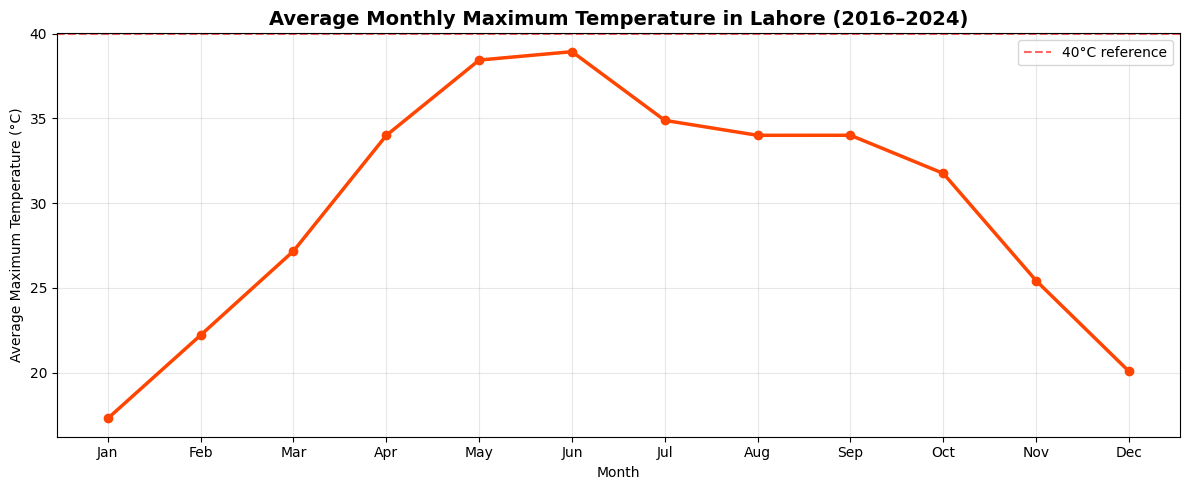

In [ ]:

# HEATSAFE - MONTHLY TEMPERATURE VISUALIZATION

import matplotlib.pyplot as plt

monthly_temp = lahore_history.groupby("month")[
    "tmax"
].mean()

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_temp.index,
    monthly_temp.values,
    marker="o",
    linewidth=2.5,
    color="orangered"
)

plt.title(
    "Average Monthly Maximum Temperature in Lahore (2016–2024)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Average Maximum Temperature (°C)")

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.grid(alpha=0.3)
plt.axhline(40, color="red", linestyle="--",
            alpha=0.6, label="40°C reference")

plt.legend()
plt.tight_layout()
plt.show()


In [20]:

# HEATSAFE - HOT DAY THRESHOLD INVESTIGATION

print("HOT DAY TEMPERATURE ANALYSIS")
print("=" * 50)

print("\nMaximum temperature on non-hot days:")
print(
    lahore_history.loc[
        lahore_history["is_hot_day"] == 0, "tmax"
    ].max()
)

print("\nMinimum temperature on hot days:")
print(
    lahore_history.loc[
        lahore_history["is_hot_day"] == 1, "tmax"
    ].min()
)

print("\nHot-day observations by maximum temperature:")
print(
    lahore_history.groupby("is_hot_day")["tmax"]
    .describe()
    .round(2)
)


HOT DAY TEMPERATURE ANALYSIS

Maximum temperature on non-hot days:
44.7

Minimum temperature on hot days:
39.1

Hot-day observations by maximum temperature:
             count   mean   std   min    25%   50%   75%   max
is_hot_day                                                    
0           3199.0  29.51  7.35  10.3  23.25  31.4  35.1  44.7
1             89.0  42.92  1.49  39.1  41.70  43.0  44.0  46.3


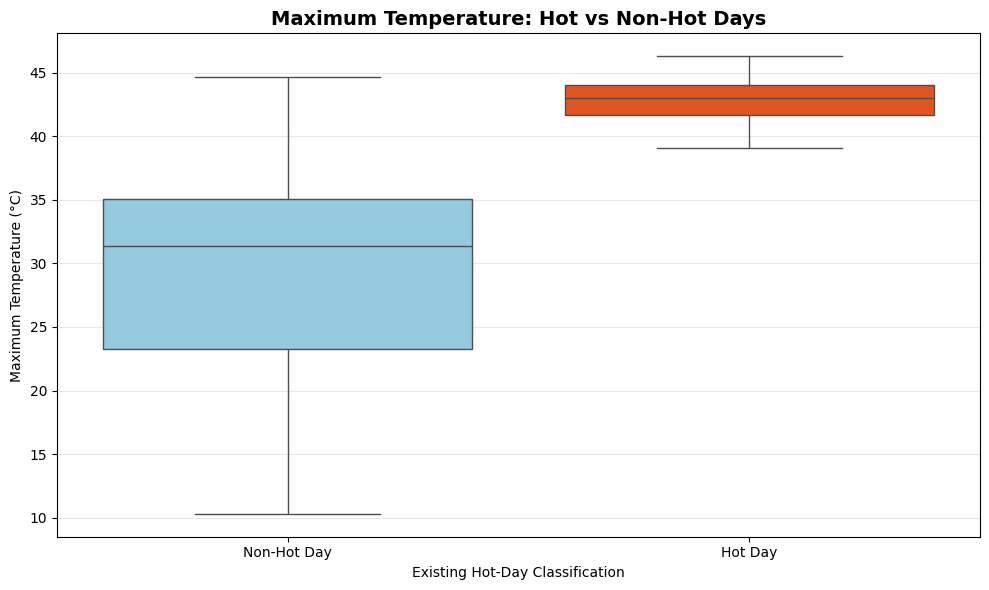

In [21]:

# HEATSAFE - HOT DAY DISTRIBUTION

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=lahore_history,
    x="is_hot_day",
    y="tmax",
    hue="is_hot_day",
    palette={0: "skyblue", 1: "orangered"},
    legend=False
)

plt.title(
    "Maximum Temperature: Hot vs Non-Hot Days",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Existing Hot-Day Classification")
plt.ylabel("Maximum Temperature (°C)")

plt.xticks([0, 1], ["Non-Hot Day", "Hot Day"])
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [24]:


# HEATSAFE - ADVANCED DATA INTEGRITY INVESTIGATION

print("=" * 65)
print("HEATSAFE: ADVANCED DATA INTEGRITY INVESTIGATION")
print("=" * 65)

# 1. Check recent dataset dates
recent = df_2024_2025.copy()

recent["date"] = pd.to_datetime(
    recent["date"], errors="coerce"
)

print("\n1. RECENT DATASET DATE RANGE")

print("Earliest:", recent["date"].min())
print("Latest:", recent["date"].max())

print("\nRows:", len(recent))
print("Unique dates:", recent["date"].nunique())

print("\nObservations per city:")
print(recent.groupby("city").size())

# 2. Investigate duplicate Lahore records
print("\n2. LAHORE DUPLICATE INVESTIGATION")

recent_lahore = recent[
    recent["city"].str.strip().str.lower() == "lahore"
].copy()

print("Lahore rows:", len(recent_lahore))
print("Unique Lahore dates:", recent_lahore["date"].nunique())

print("\nRepeated Lahore dates:")
print(
    recent_lahore[
        recent_lahore.duplicated("date", keep=False)
    ][["date", "tmin", "tmax", "tavg"]]
    .sort_values("date")
    .head(20)
)

# 3. Check whether duplicate observations have
# different weather values

print("\n3. WEATHER VALUE CONSISTENCY")

weather_columns = [
    "tmin", "tmax", "tavg", "humidity",
    "wspd", "dew_point"
]

for col in weather_columns:
    if col in recent_lahore.columns:
        print(
            col,
            "| Unique values:",
            recent_lahore[col].nunique(),
            "| Missing:",
            recent_lahore[col].isna().sum()
        )

# 4. Historical and recent date overlap
print("\n4. HISTORICAL / RECENT OVERLAP")

history = df_2000_2024.copy()

history["date"] = pd.to_datetime(
    history["date"], errors="coerce"
)

historical_lahore = history[
    history["city"].str.strip().str.lower() == "lahore"
].copy()

historical_dates = set(historical_lahore["date"])
recent_dates = set(recent_lahore["date"])

overlap = historical_dates.intersection(recent_dates)

print("Historical Lahore dates:", len(historical_dates))
print("Recent Lahore dates:", len(recent_dates))
print("Overlapping dates:", len(overlap))

# 5. Existing hot-day label investigation
print("\n5. HOT-DAY LABEL THRESHOLD INVESTIGATION")

label_analysis = (
    historical_lahore
    .groupby("is_hot_day")
    .agg(
        count=("tmax", "count"),
        minimum=("tmax", "min"),
        maximum=("tmax", "max"),
        mean=("tmax", "mean")
    )
)

display(label_analysis.round(2))

print("\nHot-day labels against possible thresholds:")

for threshold in [35, 38, 40, 42, 45]:
    actual = historical_lahore["is_hot_day"]
    threshold_label = (
        historical_lahore["tmax"] >= threshold
    ).astype(int)

    agreement = (actual == threshold_label).mean() * 100

    print(
        f"{threshold}°C threshold agreement:",
        round(agreement, 2), "%"
    )

# 6. Check impossible or suspicious values
print("\n6. PHYSICAL VALUE CHECKS")

checks = {
    "tmax below tmin": (
        historical_lahore["tmax"] <
        historical_lahore["tmin"]
    ).sum(),

    "Humidity outside 0-100": (
        (historical_lahore["humidity"] < 0) |
        (historical_lahore["humidity"] > 100)
    ).sum(),

    "Negative wind speed": (
        historical_lahore["wspd"] < 0
    ).sum(),

    "Negative precipitation": (
        historical_lahore["prcp"] < 0
    ).sum()
}

for name, count in checks.items():
    print(name + ":", count)

print("\n" + "=" * 65)
print("INVESTIGATION COMPLETE")
print("=" * 65)


HEATSAFE: ADVANCED DATA INTEGRITY INVESTIGATION

1. RECENT DATASET DATE RANGE
Earliest: 2024-09-10 00:00:00+05:00
Latest: 2024-09-10 00:00:00+05:00

Rows: 2466
Unique dates: 1

Observations per city:
city
Gilgit       411
Islamabad    411
Karachi      411
Lahore       411
Peshawar     411
Quetta       411
dtype: int64

2. LAHORE DUPLICATE INVESTIGATION
Lahore rows: 411
Unique Lahore dates: 1

Repeated Lahore dates:
                          date       tmin       tmax       tavg
822  2024-09-10 00:00:00+05:00  25.354500  32.504498  28.244081
1101 2024-09-10 00:00:00+05:00  28.154501  36.604500  31.494080
1100 2024-09-10 00:00:00+05:00  32.654500  43.004498  36.421170
1099 2024-09-10 00:00:00+05:00  30.104500  42.354500  36.660748
1098 2024-09-10 00:00:00+05:00  31.604500  43.154500  37.981580
1097 2024-09-10 00:00:00+05:00  31.404501  46.004498  39.671165
1096 2024-09-10 00:00:00+05:00  30.754500  46.404500  39.108660
1095 2024-09-10 00:00:00+05:00  33.204500  44.404500  38.744083
1094 

,count,minimum,maximum,mean
is_hot_day,,,,
0,3199,10.3,44.7,29.51
1,89,39.1,46.3,42.92



Hot-day labels against possible thresholds:
35°C threshold agreement: 75.0 %
38°C threshold agreement: 89.26 %
40°C threshold agreement: 95.04 %
42°C threshold agreement: 97.69 %
45°C threshold agreement: 97.51 %

6. PHYSICAL VALUE CHECKS
tmax below tmin: 0
Humidity outside 0-100: 0
Negative wind speed: 0
Negative precipitation: 0

INVESTIGATION COMPLETE


In [25]:

# ============================================================
# HEATSAFE - RECENT DATASET DATE FORENSICS
# ============================================================

print("=" * 65)
print("HEATSAFE: DATE FORENSICS")
print("=" * 65)

recent = df_2024_2025_original.copy()

# 1. Inspect date-related columns
date_cols = ["date", "year", "month", "day"]

print("\n1. DATE COLUMN INFORMATION")

for col in date_cols:
    print(f"\n{col}")
    print("Data type:", recent[col].dtype)
    print("Unique values:", recent[col].nunique())
    print("First 20 values:")
    print(recent[col].head(20).tolist())

# 2. Investigate date components
print("\n2. YEAR DISTRIBUTION")
print(recent["year"].value_counts().sort_index())

print("\n3. MONTH DISTRIBUTION")
print(recent["month"].value_counts().sort_index())

print("\n4. DAY DISTRIBUTION")
print(recent["day"].value_counts().sort_index())

# 3. Inspect Lahore's original row order
print("\n5. FIRST 30 ORIGINAL LAHORE RECORDS")

lahore = recent[
    recent["city"].str.strip().str.lower() == "lahore"
].copy()

display(
    lahore[
        ["date", "year", "month", "day",
         "tmin", "tmax", "tavg", "humidity",
         "wspd", "dew_point"]
    ].head(30)
)

# 4. Check whether date components reconstruct
# a different date from the date column

print("\n6. RECONSTRUCTED DATE CHECK")

reconstructed = pd.to_datetime(
    recent[["year", "month", "day"]],
    errors="coerce"
)

recorded = pd.to_datetime(
    recent["date"],
    errors="coerce",
    utc=True
).dt.tz_convert("Asia/Karachi").dt.tz_localize(None)

print("Reconstructed unique dates:",
      reconstructed.nunique())

print("Recorded unique dates:",
      recorded.nunique())

print("Matching dates:",
      (reconstructed == recorded).sum())

print("Mismatching dates:",
      (reconstructed != recorded).sum())

# 5. Inspect original uploaded CSV headers
print("\n7. ORIGINAL DATASET COLUMNS")
print(recent.columns.tolist())

# 6. Check whether records appear in chronological order
print("\n8. DATE COMPONENT COMBINATIONS")

display(
    recent.groupby(
        ["year", "month", "day"]
    ).size().reset_index(name="rows").head(30)
)

print("\n" + "=" * 65)
print("DATE FORENSICS COMPLETE")
print("=" * 65)


HEATSAFE: DATE FORENSICS

1. DATE COLUMN INFORMATION

date
Data type: object
Unique values: 1
First 20 values:
['2024-09-10 00:00:00+05:00', '2024-09-10 00:00:00+05:00', '2024-09-10 00:00:00+05:00', '2024-09-10 00:00:00+05:00', '2024-09-10 00:00:00+05:00', '2024-09-10 00:00:00+05:00', '2024-09-10 00:00:00+05:00', '2024-09-10 00:00:00+05:00', '2024-09-10 00:00:00+05:00', '2024-09-10 00:00:00+05:00', '2024-09-10 00:00:00+05:00', '2024-09-10 00:00:00+05:00', '2024-09-10 00:00:00+05:00', '2024-09-10 00:00:00+05:00', '2024-09-10 00:00:00+05:00', '2024-09-10 00:00:00+05:00', '2024-09-10 00:00:00+05:00', '2024-09-10 00:00:00+05:00', '2024-09-10 00:00:00+05:00', '2024-09-10 00:00:00+05:00']

year
Data type: int64
Unique values: 1
First 20 values:
[2024, 2024, 2024, 2024, 2024, 2024, 2024, 2024, 2024, 2024, 2024, 2024, 2024, 2024, 2024, 2024, 2024, 2024, 2024, 2024]

month
Data type: int64
Unique values: 1
First 20 values:
[9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9]

day
Data t

,date,year,month,day,tmin,tmax,tavg,humidity,wspd,dew_point
822,2024-09-10 00:00:00+05:00,2024,9,10,25.354500,32.504498,28.244081,82.191450,6.498640,24.756584
823,2024-09-10 00:00:00+05:00,2024,9,10,24.954500,32.704500,28.689919,81.286290,5.068480,24.912834
824,2024-09-10 00:00:00+05:00,2024,9,10,25.054500,35.254498,29.842001,72.581345,8.686936,24.021170
825,2024-09-10 00:00:00+05:00,2024,9,10,24.354500,34.204500,28.889914,76.801310,7.297217,24.108667
826,2024-09-10 00:00:00+05:00,2024,9,10,24.804500,32.704500,28.244080,76.210760,8.976499,23.464918
827,2024-09-10 00:00:00+05:00,2024,9,10,24.804500,34.254498,28.800331,69.740990,5.991154,22.227419
828,2024-09-10 00:00:00+05:00,2024,9,10,23.704500,34.354500,28.519087,66.738884,5.076504,21.198250
829,2024-09-10 00:00:00+05:00,2024,9,10,23.054500,35.204500,29.035750,68.302230,5.303783,22.064919
830,2024-09-10 00:00:00+05:00,2024,9,10,23.604500,34.654500,28.550333,70.949196,5.089918,22.319082
831,2024-09-10 00:00:00+05:00,2024,9,10,23.704500,32.404500,27.039915,74.987940,7.334894,21.900330



6. RECONSTRUCTED DATE CHECK
Reconstructed unique dates: 1
Recorded unique dates: 1
Matching dates: 2466
Mismatching dates: 0

7. ORIGINAL DATASET COLUMNS
['date', 'year', 'month', 'day', 'dayofweek', 'is_weekend', 'season', 'city', 'region', 'latitude', 'longitude', 'elevation', 'tmin', 'tmax', 'tavg', 'prcp', 'wspd', 'humidity', 'pressure', 'dew_point', 'cloud_cover', 'visibility', 'temp_range', 'is_hot_day', 'is_cold_day', 'rainfall_intensity', 'wind_category']

8. DATE COMPONENT COMBINATIONS


,year,month,day,rows
0,2024,9,10,2466



DATE FORENSICS COMPLETE


In [26]:

# ============================================================
# HEATSAFE - HISTORICAL LAHORE DATA PREPARATION
# ============================================================

import pandas as pd
import numpy as np

print("=" * 55)
print("HEATSAFE: HISTORICAL DATA PREPARATION")
print("=" * 55)

# Work exclusively with historical data
lahore = df_2000_2024.copy()

# Filter Lahore
lahore = lahore[
    lahore["city"].str.strip().str.lower() == "lahore"
].copy()

# Convert dates
lahore["date"] = pd.to_datetime(
    lahore["date"],
    errors="coerce"
)

# Sort chronologically
lahore = lahore.sort_values("date")

# Remove exact duplicate rows only
lahore = lahore.drop_duplicates()

# Reset index
lahore = lahore.reset_index(drop=True)

# Verify data
print("\nDATASET SUMMARY")
print("Total observations:", len(lahore))
print("Unique dates:", lahore["date"].nunique())
print("Start date:", lahore["date"].min())
print("End date:", lahore["date"].max())

print("\nYEAR DISTRIBUTION")
print(lahore.groupby(
    lahore["date"].dt.year
).size())

print("\nMISSING VALUES")
print(lahore.isnull().sum())

print("\nTEMPERATURE SUMMARY")
display(
    lahore[["tmin", "tmax", "tavg"]]
    .describe()
    .round(2)
)

print("\nDATASET READY!")


HEATSAFE: HISTORICAL DATA PREPARATION

DATASET SUMMARY
Total observations: 3288
Unique dates: 3288
Start date: 2016-01-01 00:00:00
End date: 2024-12-31 00:00:00

YEAR DISTRIBUTION
date
2016    366
2017    365
2018    365
2019    365
2020    366
2021    365
2022    365
2023    365
2024    366
dtype: int64

MISSING VALUES
date                     0
year                     0
month                    0
day                      0
dayofweek                0
is_weekend               0
season                   0
city                     0
region                   0
latitude                 0
longitude                0
elevation                0
tmin                     0
tmax                     0
tavg                     0
prcp                     0
wspd                     0
humidity                 0
pressure                 0
dew_point                0
cloud_cover              0
visibility            3288
temp_range               0
is_hot_day               0
is_cold_day              0
rai

,tmin,tmax,tavg
count,3288.00,3288.00,3288.00
mean,18.22,29.87,23.67
std,7.84,7.57,7.72
min,1.10,10.30,5.30
25%,11.30,23.50,16.70
50%,19.20,31.65,25.60
75%,25.60,35.40,30.10
max,32.30,46.30,38.50



DATASET READY!


##Phase 2: Heat-Risk Classification and Data Preparation
Weather observations are converted into four experimental heat-risk categories: Low, Moderate, High, and Extreme. The dataset is then prepared for next-day prediction by creating target labels, selecting relevant weather features, and preparing the training and testing data.

In [27]:

# ============================================================
# HEATSAFE - HEAT RISK CLASSIFICATION
# ============================================================

print("=" * 55)
print("HEATSAFE: DEVELOPING HEAT-RISK CATEGORIES")
print("=" * 55)

def classify_heat(temp):
    if temp < 30:
        return "Low"
    elif temp < 35:
        return "Moderate"
    elif temp < 40:
        return "High"
    else:
        return "Extreme"

lahore["heat_risk"] = lahore["tmax"].apply(
    classify_heat
)

# Numerical labels for machine learning
risk_mapping = {
    "Low": 0,
    "Moderate": 1,
    "High": 2,
    "Extreme": 3
}

lahore["heat_risk_encoded"] = (
    lahore["heat_risk"].map(risk_mapping)
)

print("\nHEAT-RISK DISTRIBUTION")

display(
    lahore["heat_risk"]
    .value_counts()
    .reindex(["Low", "Moderate", "High", "Extreme"])
    .rename("Number of Days")
    .to_frame()
)

print("\nPERCENTAGE DISTRIBUTION")

display(
    (
        lahore["heat_risk"]
        .value_counts(normalize=True)
        .reindex(["Low", "Moderate", "High", "Extreme"])
        * 100
    ).round(2).rename("Percentage").to_frame()
)

print("\nSAMPLE CLASSIFIED OBSERVATIONS")

display(
    lahore[
        ["date", "tmin", "tmax", "tavg",
         "humidity", "heat_risk"]
    ].head(15)
)

print("\nHEAT-RISK CLASSIFICATION COMPLETE!")


HEATSAFE: DEVELOPING HEAT-RISK CATEGORIES

HEAT-RISK DISTRIBUTION


,Number of Days
heat_risk,
Low,1407
Moderate,970
High,661
Extreme,250



PERCENTAGE DISTRIBUTION


,Percentage
heat_risk,
Low,42.79
Moderate,29.50
High,20.10
Extreme,7.60



SAMPLE CLASSIFIED OBSERVATIONS


,date,tmin,tmax,tavg,humidity,heat_risk
0,2016-01-01,9.9,20.9,14.5,64,Low
1,2016-01-02,6.2,20.6,13.1,69,Low
2,2016-01-03,7.6,21.6,14.2,65,Low
3,2016-01-04,9.5,20.9,14.7,73,Low
4,2016-01-05,8.9,21.9,14.9,77,Low
5,2016-01-06,9.1,20.6,14.4,76,Low
6,2016-01-07,8.5,21.3,14.6,74,Low
7,2016-01-08,8.5,21.1,14.2,71,Low
8,2016-01-09,7.0,21.1,14.1,64,Low
9,2016-01-10,8.0,21.2,14.1,70,Low



HEAT-RISK CLASSIFICATION COMPLETE!


In [28]:

# ============================================================
# HEATSAFE - NEXT-DAY PREDICTION DATASET
# ============================================================

import pandas as pd
import numpy as np

ml_data = lahore.copy().sort_values("date").reset_index(drop=True)

# Tomorrow's maximum temperature and risk
ml_data["target_tmax"] = ml_data["tmax"].shift(-1)
ml_data["target_risk"] = ml_data["heat_risk_encoded"].shift(-1)

# Today's information used to predict tomorrow
ml_data["previous_tmax"] = ml_data["tmax"]
ml_data["previous_tavg"] = ml_data["tavg"]
ml_data["previous_tmin"] = ml_data["tmin"]
ml_data["previous_humidity"] = ml_data["humidity"]
ml_data["previous_dew_point"] = ml_data["dew_point"]
ml_data["previous_wind"] = ml_data["wspd"]
ml_data["previous_pressure"] = ml_data["pressure"]
ml_data["previous_rainfall"] = ml_data["prcp"]
ml_data["previous_cloud_cover"] = ml_data["cloud_cover"]

# Calendar information for the target day
ml_data["target_month"] = (
    ml_data["date"].shift(-1).dt.month
)

ml_data["target_dayofweek"] = (
    ml_data["date"].shift(-1).dt.dayofweek
)

# Remove final row (no next-day target)
ml_data = ml_data.dropna(
    subset=["target_tmax", "target_risk"]
).copy()

ml_data["target_risk"] = (
    ml_data["target_risk"].astype(int)
)

print("NEXT-DAY DATASET CREATED")
print("=" * 50)

print("Total observations:", len(ml_data))

print("\nPrediction target distribution:")
print(
    ml_data["target_risk"]
    .value_counts()
    .sort_index()
)

print("\nDate range:")
print(ml_data["date"].min(), "to", ml_data["date"].max())

display(ml_data.head())


NEXT-DAY DATASET CREATED
Total observations: 3287

Prediction target distribution:
target_risk
0    1406
1     970
2     661
3     250
Name: count, dtype: int64

Date range:
2016-01-01 00:00:00 to 2024-12-30 00:00:00


,date,year,month,day,dayofweek,is_weekend,season,city,region,latitude,...,previous_tavg,previous_tmin,previous_humidity,previous_dew_point,previous_wind,previous_pressure,previous_rainfall,previous_cloud_cover,target_month,target_dayofweek
0,2016-01-01,2016,1,1,4,0,Winter,Lahore,Punjab,31.5497,...,14.5,9.9,64,7.3,6.6,1021.0,0.0,46,1.0,5.0
1,2016-01-02,2016,1,2,5,1,Winter,Lahore,Punjab,31.5497,...,13.1,6.2,69,6.8,10.8,1021.9,0.0,37,1.0,6.0
2,2016-01-03,2016,1,3,6,1,Winter,Lahore,Punjab,31.5497,...,14.2,7.6,65,6.9,10.4,1018.7,0.0,34,1.0,0.0
3,2016-01-04,2016,1,4,0,0,Winter,Lahore,Punjab,31.5497,...,14.7,9.5,73,9.5,7.8,1018.7,0.6,63,1.0,1.0
4,2016-01-05,2016,1,5,1,0,Winter,Lahore,Punjab,31.5497,...,14.9,8.9,77,10.3,9.6,1018.6,0.0,27,1.0,2.0


##Phase 3: Machine Learning Development and Evaluation
This phase involves developing and comparing machine learning models to predict the next day's heat-risk category. Random Forest, Decision Tree, and Logistic Regression are trained and evaluated using accuracy, Macro F1-score, balanced accuracy, precision, and recall.

In [29]:

# ============================================================
# HEATSAFE - RANDOM FOREST CLASSIFICATION
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

features = [
    "previous_tmax",
    "previous_tavg",
    "previous_tmin",
    "previous_humidity",
    "previous_dew_point",
    "previous_wind",
    "previous_pressure",
    "previous_rainfall",
    "previous_cloud_cover",
    "target_month",
    "target_dayofweek"
]

X = ml_data[features]
y = ml_data["target_risk"]

# Chronological split
train_mask = ml_data["date"] < "2023-01-01"
test_mask = ml_data["date"] >= "2023-01-01"

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

# Train model
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=4,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Predictions
y_pred = rf_model.predict(X_test)

print("\nRANDOM FOREST RESULTS")
print("=" * 50)

print("Accuracy:", round(
    accuracy_score(y_test, y_pred) * 100, 2
), "%")

print("Macro F1:", round(
    f1_score(y_test, y_pred, average="macro") * 100, 2
), "%")

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=["Low", "Moderate", "High", "Extreme"],
    zero_division=0
))


Training observations: 2557
Testing observations: 730

RANDOM FOREST RESULTS
Accuracy: 85.34 %
Macro F1: 82.72 %

CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Low       0.97      0.92      0.95       329
    Moderate       0.80      0.81      0.80       228
        High       0.69      0.76      0.72       129
     Extreme       0.81      0.86      0.84        44

    accuracy                           0.85       730
   macro avg       0.82      0.84      0.83       730
weighted avg       0.86      0.85      0.86       730



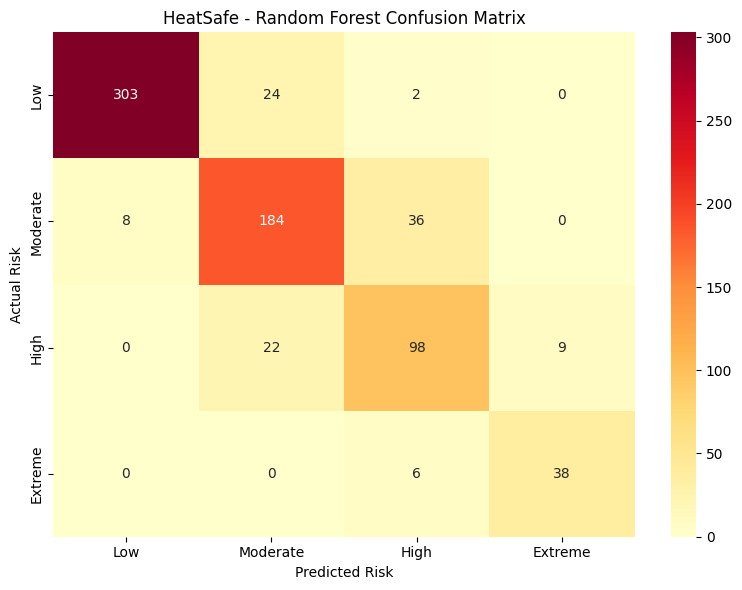

In [30]:

import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    xticklabels=["Low", "Moderate", "High", "Extreme"],
    yticklabels=["Low", "Moderate", "High", "Extreme"]
)

plt.title("HeatSafe - Random Forest Confusion Matrix")
plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")

plt.tight_layout()
plt.show()


HEATSAFE: FALSE NEGATIVE INVESTIGATION


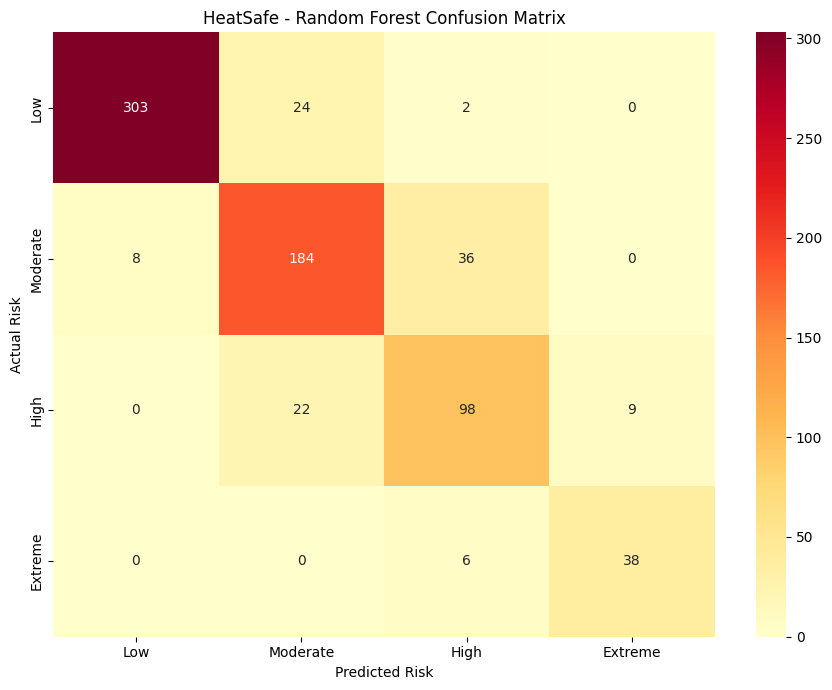


DANGEROUS DAY ANALYSIS
---------------------------------------------
Actual dangerous days: 173
Correctly detected: 151
Missed dangerous days: 22
Dangerous-day recall: 87.28 %

MISSED DANGEROUS DAYS


,date,target_tmax,actual_category,predicted_category
3054,2024-05-12,37.5,High,Moderate
2694,2023-05-18,36.8,High,Moderate
3133,2024-07-30,36.8,High,Moderate
3132,2024-07-29,36.2,High,Moderate
2797,2023-08-29,36.1,High,Moderate
3036,2024-04-24,35.9,High,Moderate
2810,2023-09-11,35.9,High,Moderate
2657,2023-04-11,35.8,High,Moderate
3044,2024-05-02,35.8,High,Moderate
2685,2023-05-09,35.6,High,Moderate



EXTREME DAY ANALYSIS
---------------------------------------------
Actual Extreme days: 44
Missed Extreme days: 6
Extreme recall: 86.36 %

MISSED EXTREME DAYS


,date,target_tmax,actual_category,predicted_category
3057,2024-05-15,41.1,Extreme,High
2728,2023-06-21,41.0,Extreme,High
3081,2024-06-08,40.2,Extreme,High
2695,2023-05-19,40.1,Extreme,High
3056,2024-05-14,40.1,Extreme,High
3095,2024-06-22,40.1,Extreme,High



FALSE NEGATIVE INVESTIGATION COMPLETE


In [31]:

# ============================================================
# HEATSAFE - DANGEROUS DAY FAILURE ANALYSIS
# ============================================================

from sklearn.metrics import (
    confusion_matrix,
    recall_score,
    precision_score
)
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 60)
print("HEATSAFE: FALSE NEGATIVE INVESTIGATION")
print("=" * 60)

risk_names = {
    0: "Low",
    1: "Moderate",
    2: "High",
    3: "Extreme"
}

# 1. Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    xticklabels=["Low", "Moderate", "High", "Extreme"],
    yticklabels=["Low", "Moderate", "High", "Extreme"]
)

plt.title("HeatSafe - Random Forest Confusion Matrix")
plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")
plt.tight_layout()
plt.show()

# 2. Build prediction results
results = ml_data.loc[y_test.index, [
    "date", "target_tmax", "target_risk"
]].copy()

results["predicted_risk"] = y_pred

results["actual_category"] = (
    results["target_risk"].map(risk_names)
)

results["predicted_category"] = (
    results["predicted_risk"].map(risk_names)
)

# 3. Identify dangerous days
# Experimental definition: High or Extreme

actual_dangerous = results["target_risk"] >= 2
predicted_dangerous = results["predicted_risk"] >= 2

missed_dangerous = results[
    actual_dangerous & ~predicted_dangerous
].copy()

correctly_detected = results[
    actual_dangerous & predicted_dangerous
]

total_dangerous = actual_dangerous.sum()

print("\nDANGEROUS DAY ANALYSIS")
print("-" * 45)

print("Actual dangerous days:", total_dangerous)

print("Correctly detected:",
      len(correctly_detected))

print("Missed dangerous days:",
      len(missed_dangerous))

print("Dangerous-day recall:",
      round(
          recall_score(
              actual_dangerous,
              predicted_dangerous
          ) * 100, 2
      ), "%")

print("\nMISSED DANGEROUS DAYS")

display(
    missed_dangerous[
        ["date", "target_tmax",
         "actual_category", "predicted_category"]
    ].sort_values("target_tmax", ascending=False)
)

# 4. Investigate Extreme days specifically

extreme_actual = results["target_risk"] == 3

missed_extreme = results[
    extreme_actual &
    (results["predicted_risk"] < 3)
].copy()

print("\nEXTREME DAY ANALYSIS")
print("-" * 45)

print("Actual Extreme days:", extreme_actual.sum())

print("Missed Extreme days:", len(missed_extreme))

print("Extreme recall:",
      round(
          recall_score(
              extreme_actual,
              results["predicted_risk"] == 3
          ) * 100, 2
      ), "%")

print("\nMISSED EXTREME DAYS")

display(
    missed_extreme[
        ["date", "target_tmax",
         "actual_category", "predicted_category"]
    ].sort_values("target_tmax", ascending=False)
)

print("\nFALSE NEGATIVE INVESTIGATION COMPLETE")


HEATSAFE: MOST IMPORTANT PREDICTION FACTORS


,Feature,Importance
0,previous_tmax,0.3194
1,previous_tavg,0.2351
2,previous_tmin,0.1144
3,previous_humidity,0.0979
6,previous_pressure,0.0797
9,target_month,0.0464
4,previous_dew_point,0.0410
8,previous_cloud_cover,0.0284
5,previous_wind,0.0192
7,previous_rainfall,0.0127


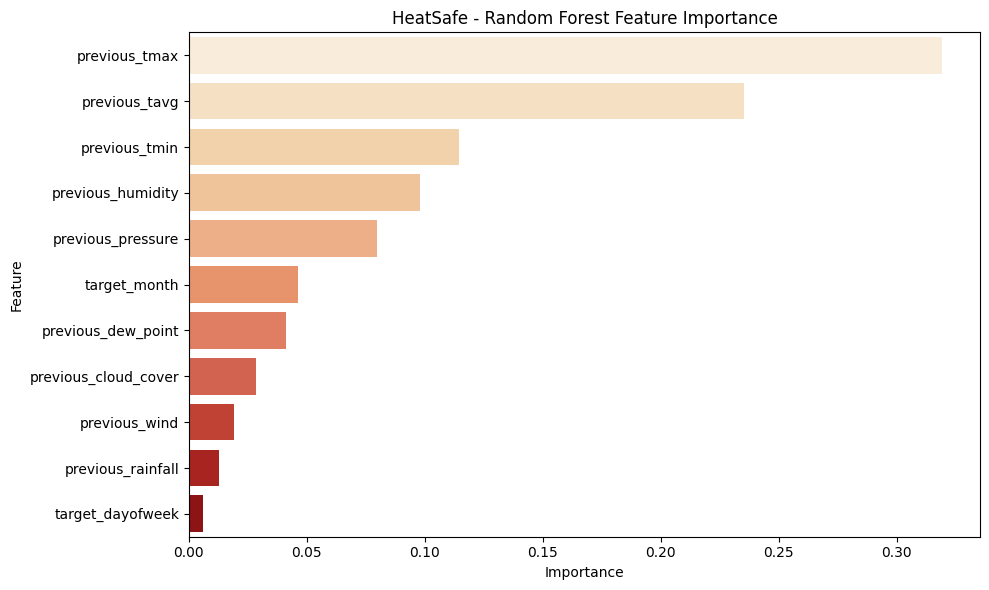

In [32]:

# ============================================================
# HEATSAFE - MODEL FEATURE IMPORTANCE
# ============================================================

importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    "Importance", ascending=False
)

print("HEATSAFE: MOST IMPORTANT PREDICTION FACTORS")

display(importance.round(4))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="OrRd",
    legend=False
)

plt.title(
    "HeatSafe - Random Forest Feature Importance"
)

plt.tight_layout()
plt.show()


In [33]:

# HEATSAFE - MODEL COMPARISON
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

# Use existing next-day dataset
data = ml_data.copy()

# Chronological split
train_mask = data["date"] < "2023-01-01"
test_mask = data["date"] >= "2023-01-01"

X_train = data.loc[train_mask, features]
X_test = data.loc[test_mask, features]

y_train = data.loc[train_mask, "target_risk"]
y_test = data.loc[test_mask, "target_risk"]

# Define models
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=4,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        class_weight="balanced",
        random_state=42
    ),

    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        )
    )
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        )
    })

comparison = pd.DataFrame(results)

print("HEATSAFE MODEL COMPARISON")
display(comparison.round(4))


HEATSAFE MODEL COMPARISON


,Model,Accuracy,Macro F1,Balanced Accuracy
0,Random Forest,0.8534,0.8272,0.8378
1,Decision Tree,0.8082,0.7775,0.8013
2,Logistic Regression,0.8603,0.8303,0.8417


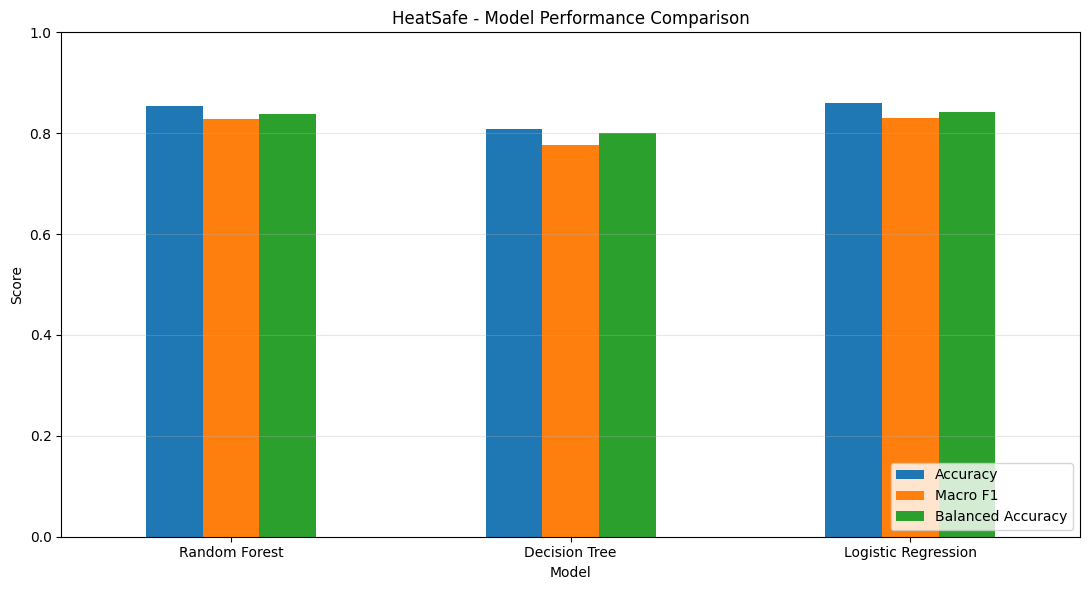

In [34]:

comparison.set_index("Model")[
    ["Accuracy", "Macro F1", "Balanced Accuracy"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("HeatSafe - Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [36]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix
import pandas as pd

# Train models using your existing training data
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=4,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

dt_model = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)

lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    )
)

rf_model.fit(X_train, y_train)
dt_model.fit(X_train, y_train)
lr_model.fit(X_train, y_train)

models = {
    "Random Forest": rf_model,
    "Decision Tree": dt_model,
    "Logistic Regression": lr_model
}

results = []

for name, model in models.items():
    pred = model.predict(X_test)

    actual = (y_test >= 2).astype(int)
    predicted = (pred >= 2).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()

    results.append({
        "Model": name,
        "Dangerous Recall": tp / (tp + fn) if tp + fn else 0,
        "Dangerous Precision": tp / (tp + fp) if tp + fp else 0,
        "False Negatives": fn
    })

display(pd.DataFrame(results).round(4))

,Model,Dangerous Recall,Dangerous Precision,False Negatives
0,Random Forest,0.8728,0.7989,22
1,Decision Tree,0.7399,0.7619,45
2,Logistic Regression,0.8266,0.8462,30


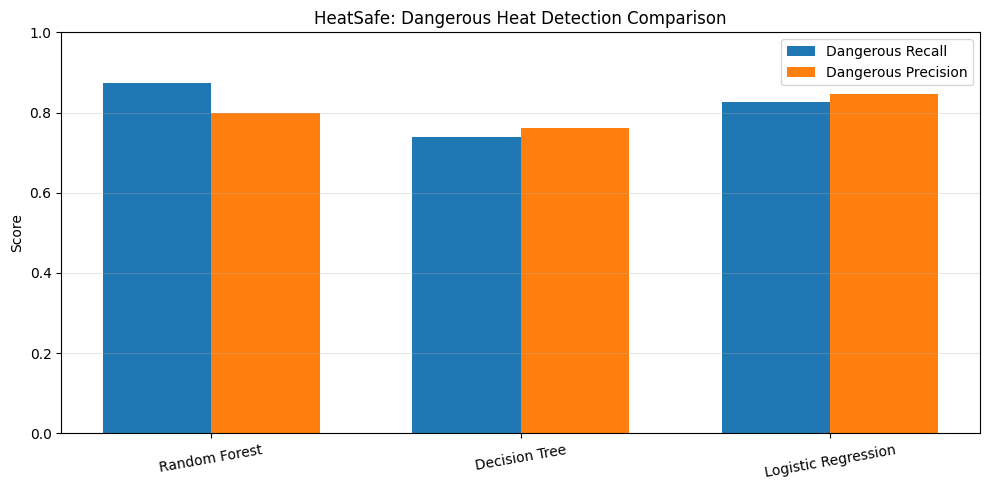

In [38]:
import matplotlib.pyplot as plt
import numpy as np

models = ["Random Forest", "Decision Tree", "Logistic Regression"]

recall = [0.8728, 0.7399, 0.8266]
precision = [0.7989, 0.7619, 0.8462]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(x - width/2, recall, width, label="Dangerous Recall")
plt.bar(x + width/2, precision, width, label="Dangerous Precision")

plt.xticks(x, models, rotation=10)
plt.ylabel("Score")
plt.title("HeatSafe: Dangerous Heat Detection Comparison")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

##Phase 4: HeatSafe Prediction System and Visualization
The trained machine learning model is integrated into an interactive HeatSafe prediction system. Users can enter weather conditions or retrieve Lahore weather data through the Open-Meteo API to generate a next-day heat-risk prediction.

In [39]:
import pandas as pd

# Risk category mapping
risk_labels = {
    0: "Low",
    1: "Moderate",
    2: "High",
    3: "Extreme"
}

def predict_heat_risk(
    tmax, tavg, tmin, humidity, dew_point,
    wind, pressure, rainfall, cloud_cover,
    target_month, target_dayofweek
):
    input_data = pd.DataFrame([{
        "previous_tmax": tmax,
        "previous_tavg": tavg,
        "previous_tmin": tmin,
        "previous_humidity": humidity,
        "previous_dew_point": dew_point,
        "previous_wind": wind,
        "previous_pressure": pressure,
        "previous_rainfall": rainfall,
        "previous_cloud_cover": cloud_cover,
        "target_month": target_month,
        "target_dayofweek": target_dayofweek
    }])

    prediction = rf_model.predict(input_data)[0]
    probabilities = rf_model.predict_proba(input_data)[0]

    print("🌡️ HEATSAFE PREDICTION")
    print("----------------------")
    print("Predicted Risk:", risk_labels[int(prediction)])
    print("Model Confidence:", round(max(probabilities) * 100, 2), "%")
    print("Experimental prediction — not an official safety warning.")

# Example test prediction
predict_heat_risk(
    tmax=38,
    tavg=32,
    tmin=27,
    humidity=65,
    dew_point=24,
    wind=12,
    pressure=1005,
    rainfall=0,
    cloud_cover=30,
    target_month=6,
    target_dayofweek=1
)

🌡️ HEATSAFE PREDICTION
----------------------
Predicted Risk: High
Model Confidence: 74.65 %
Experimental prediction — not an official safety warning.


In [42]:
import ipywidgets as widgets
from IPython.display import display, clear_output

fields = {
    "tmax": (38, "Previous maximum temperature (°C)"),
    "tavg": (32, "Previous average temperature (°C)"),
    "tmin": (27, "Previous minimum temperature (°C)"),
    "humidity": (65, "Humidity (%)"),
    "dew_point": (24, "Dew point (°C)"),
    "wind": (12, "Wind speed (km/h)"),
    "pressure": (1005, "Pressure (hPa)"),
    "rainfall": (0, "Rainfall (mm)"),
    "cloud_cover": (30, "Cloud cover (%)"),
    "target_month": (6, "Target month (1–12)"),
    "target_dayofweek": (1, "Target day (0=Monday)")
}

inputs = {}

for key, (default, label) in fields.items():
    inputs[key] = widgets.FloatText(
        value=default,
        description=label,
        style={"description_width": "initial"},
        layout=widgets.Layout(width="450px")
    )

button = widgets.Button(
    description="Predict Heat Risk",
    button_style="success"
)

output = widgets.Output()

def run_prediction(_):
    with output:
        clear_output()
        values = {key: field.value for key, field in inputs.items()}

        if not (1 <= values["target_month"] <= 12):
            print("Please enter a month from 1 to 12.")
            return

        if not (0 <= values["target_dayofweek"] <= 6):
            print("Please enter a day from 0 to 6.")
            return

        predict_heat_risk(**values)

button.on_click(run_prediction)

display(widgets.VBox([
    widgets.HTML("<h2>HeatSafe Dashboard</h2>"),
    *inputs.values(),
    button,
    output
]))

In [43]:
import requests
import pandas as pd
from datetime import datetime, timedelta
from zoneinfo import ZoneInfo

# Lahore coordinates
LATITUDE = 31.5204
LONGITUDE = 74.3587
TIMEZONE = "Asia/Karachi"

# Get today's forecast to use as previous-day weather
# features for predicting tomorrow.
today = datetime.now(ZoneInfo(TIMEZONE)).date()
tomorrow = today + timedelta(days=1)

url = "https://api.open-meteo.com/v1/forecast"

params = {
    "latitude": LATITUDE,
    "longitude": LONGITUDE,
    "timezone": TIMEZONE,
    "forecast_days": 2,
    "daily": [
        "temperature_2m_max",
        "temperature_2m_mean",
        "temperature_2m_min",
        "precipitation_sum"
    ],
    "hourly": [
        "relative_humidity_2m",
        "dew_point_2m",
        "wind_speed_10m",
        "surface_pressure",
        "cloud_cover"
    ]
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()
weather = response.json()

# Today's forecast
daily = weather["daily"]
hourly = weather["hourly"]

day_values = [
    i for i, t in enumerate(hourly["time"])
    if t.startswith(str(today))
]

if not day_values:
    raise ValueError("Today's hourly weather data is unavailable.")

def hourly_average(key):
    values = [hourly[key][i] for i in day_values]
    values = [v for v in values if v is not None]
    if not values:
        raise ValueError(f"No data available for {key}")
    return sum(values) / len(values)

day_index = daily["time"].index(str(today))

# Build model inputs
weather_inputs = {
    "tmax": daily["temperature_2m_max"][day_index],
    "tavg": daily["temperature_2m_mean"][day_index],
    "tmin": daily["temperature_2m_min"][day_index],
    "humidity": hourly_average("relative_humidity_2m"),
    "dew_point": hourly_average("dew_point_2m"),
    "wind": hourly_average("wind_speed_10m"),
    "pressure": hourly_average("surface_pressure"),
    "rainfall": daily["precipitation_sum"][day_index],
    "cloud_cover": hourly_average("cloud_cover"),
    "target_month": tomorrow.month,
    "target_dayofweek": tomorrow.weekday()
}

print("Lahore weather fetched successfully!")
print("Prediction date:", tomorrow)

predict_heat_risk(**weather_inputs)

Lahore weather fetched successfully!
Prediction date: 2026-11-15
🌡️ HEATSAFE PREDICTION
----------------------
Predicted Risk: Low
Model Confidence: 70.25 %
Experimental prediction — not an official safety warning.


In [44]:
import pandas as pd
import os
from datetime import datetime

history_file = "heatsafe_prediction_history.csv"

new_record = pd.DataFrame([{
    "prediction_date": str(tomorrow),
    "predicted_risk": risk_labels[
        int(rf_model.predict(pd.DataFrame([{
            "previous_tmax": weather_inputs["tmax"],
            "previous_tavg": weather_inputs["tavg"],
            "previous_tmin": weather_inputs["tmin"],
            "previous_humidity": weather_inputs["humidity"],
            "previous_dew_point": weather_inputs["dew_point"],
            "previous_wind": weather_inputs["wind"],
            "previous_pressure": weather_inputs["pressure"],
            "previous_rainfall": weather_inputs["rainfall"],
            "previous_cloud_cover": weather_inputs["cloud_cover"],
            "target_month": weather_inputs["target_month"],
            "target_dayofweek": weather_inputs["target_dayofweek"]
        }]))[0])
    ],
    "confidence": round(
        max(rf_model.predict_proba(pd.DataFrame([{
            "previous_tmax": weather_inputs["tmax"],
            "previous_tavg": weather_inputs["tavg"],
            "previous_tmin": weather_inputs["tmin"],
            "previous_humidity": weather_inputs["humidity"],
            "previous_dew_point": weather_inputs["dew_point"],
            "previous_wind": weather_inputs["wind"],
            "previous_pressure": weather_inputs["pressure"],
            "previous_rainfall": weather_inputs["rainfall"],
            "previous_cloud_cover": weather_inputs["cloud_cover"],
            "target_month": weather_inputs["target_month"],
            "target_dayofweek": weather_inputs["target_dayofweek"]
        }]))[0]) * 100, 2
    )
}])

if os.path.exists(history_file):
    old_history = pd.read_csv(history_file)
    history = pd.concat([old_history, new_record], ignore_index=True)
    history = history.drop_duplicates(
        subset=["prediction_date"], keep="last"
    )
else:
    history = new_record

history.to_csv(history_file, index=False)

display(history.tail(10))
print("Prediction history saved!")

,prediction_date,predicted_risk,confidence
0,2026-11-15,Low,70.25


Prediction history saved!


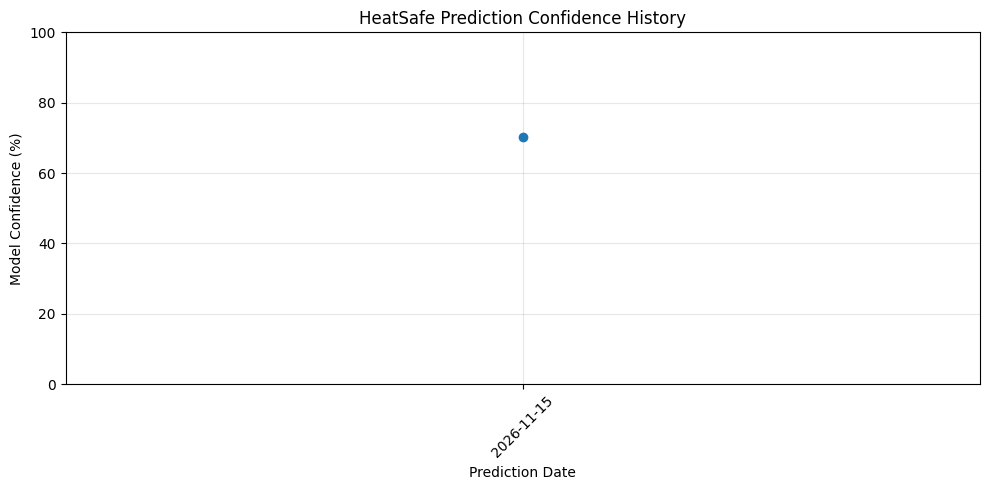

Total predictions: 1


,prediction_date,predicted_risk,confidence
0,2026-11-15,Low,70.25


In [45]:
import pandas as pd
import matplotlib.pyplot as plt

history = pd.read_csv("heatsafe_prediction_history.csv")

risk_order = ["Low", "Moderate", "High", "Extreme"]

history["predicted_risk"] = pd.Categorical(
    history["predicted_risk"],
    categories=risk_order,
    ordered=True
)

history = history.sort_values("prediction_date")

plt.figure(figsize=(10, 5))

plt.plot(
    history["prediction_date"],
    history["confidence"],
    marker="o"
)

plt.title("HeatSafe Prediction Confidence History")
plt.xlabel("Prediction Date")
plt.ylabel("Model Confidence (%)")
plt.ylim(0, 100)
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Total predictions:", len(history))
display(history.tail(10))

In [46]:
import pandas as pd

summary = pd.DataFrame({
    "Metric": [
        "Best Model",
        "Accuracy",
        "Macro F1",
        "Balanced Accuracy",
        "Dangerous Day Recall",
        "Dangerous Day Precision",
        "False Negatives",
        "Historical Dataset",
        "Historical Observations",
        "Live Weather Integration"
    ],
    "Result": [
        "Logistic Regression",
        "86.03%",
        "83.03%",
        "84.17%",
        "87.28% (Random Forest)",
        "79.89% (Random Forest)",
        "22 (Random Forest)",
        "Lahore, 2016–2024",
        "3,288",
        "Open-Meteo"
    ]
})

display(summary)

summary.to_csv("HeatSafe_Final_Summary.csv", index=False)

print("HeatSafe final summary saved!")

,Metric,Result
0,Best Model,Logistic Regression
1,Accuracy,86.03%
2,Macro F1,83.03%
3,Balanced Accuracy,84.17%
4,Dangerous Day Recall,87.28% (Random Forest)
5,Dangerous Day Precision,79.89% (Random Forest)
6,False Negatives,22 (Random Forest)
7,Historical Dataset,"Lahore, 2016–2024"
8,Historical Observations,"3,288"
9,Live Weather Integration,Open-Meteo


HeatSafe final summary saved!
